# Chapter 5 — Features and correspondence

Companion notebook to **Chapter 5**. Corners from the structure tensor, oriented BRIEF descriptors, matching with the
ratio test, Lucas–Kanade tracking and RANSAC — all from scratch in `vslam.features`, `vslam.flow` and `vslam.ransac`,
and compared with OpenCV's ORB at the end.

The images are synthetic so that the ground truth is exact: a *garden* (man-made shapes) and a *lawn* (thousands of
grass blades, optionally moved by the wind). A second view of a planar texture is a homography, so every pixel's true
correspondence is known.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import cv2
import numpy as np
import matplotlib.pyplot as plt
from vslam import features as ft, flow, image, ransac
from ch05_features import K, match_views

np.set_printoptions(precision=4, suppress=True)
garden = image.garden_texture(rng=np.random.default_rng(0))
lawn = image.lawn_texture(rng=np.random.default_rng(0))
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The structure tensor (Proposition 5.1)

$M$ summarises how the patch changes when shifted. Flat regions have two small eigenvalues, edges one large and one
small, corners two large ones. Below, every pixel of the garden image is a point $(\lambda_{\min},\lambda_{\max})$.

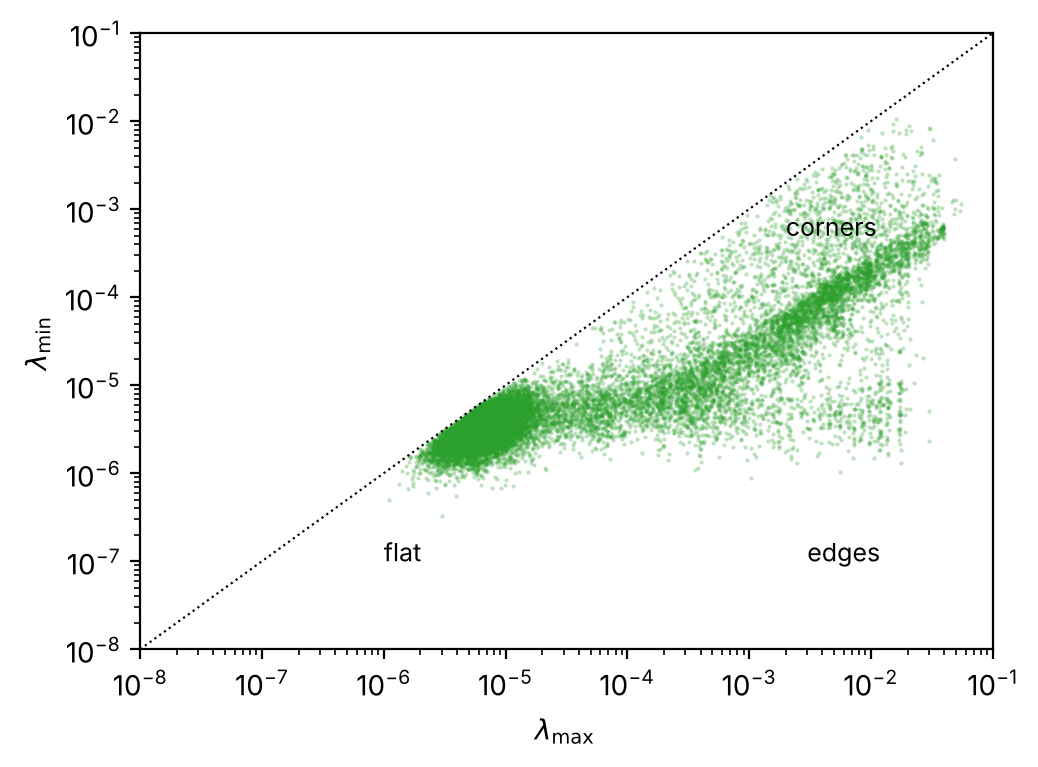

In [2]:
A, B, C = ft.structure_tensor(garden, 1.5)
lmin, lmax = ft.eigenvalues(A, B, C)
sel = np.random.default_rng(0).choice(lmin.size, 20000, replace=False)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(lmax.ravel()[sel] + 1e-8, lmin.ravel()[sel] + 1e-8, ".", ms=1, alpha=0.3, color="tab:green")
ax.plot([1e-8, 1], [1e-8, 1], "k:", lw=0.8)
ax.set_xlabel(r"$\lambda_{\max}$"); ax.set_ylabel(r"$\lambda_{\min}$")
ax.text(1e-6, 1e-7, "flat", fontsize=9); ax.text(3e-3, 1e-7, "edges", fontsize=9)
ax.text(2e-3, 5e-4, "corners", fontsize=9)
ax.set_ylim(1e-8, 1e-1); ax.set_xlim(1e-8, 1e-1);

## 2. Orientation and steered BRIEF (Proposition 5.3)

Rotate the garden by an arbitrary angle about its centre, and compare the descriptor of the centre point in both
images. Without steering, BRIEF falls apart beyond ~15°; steered by the intensity-centroid angle it stays close to the
original at any angle (the residual comes from interpolation).

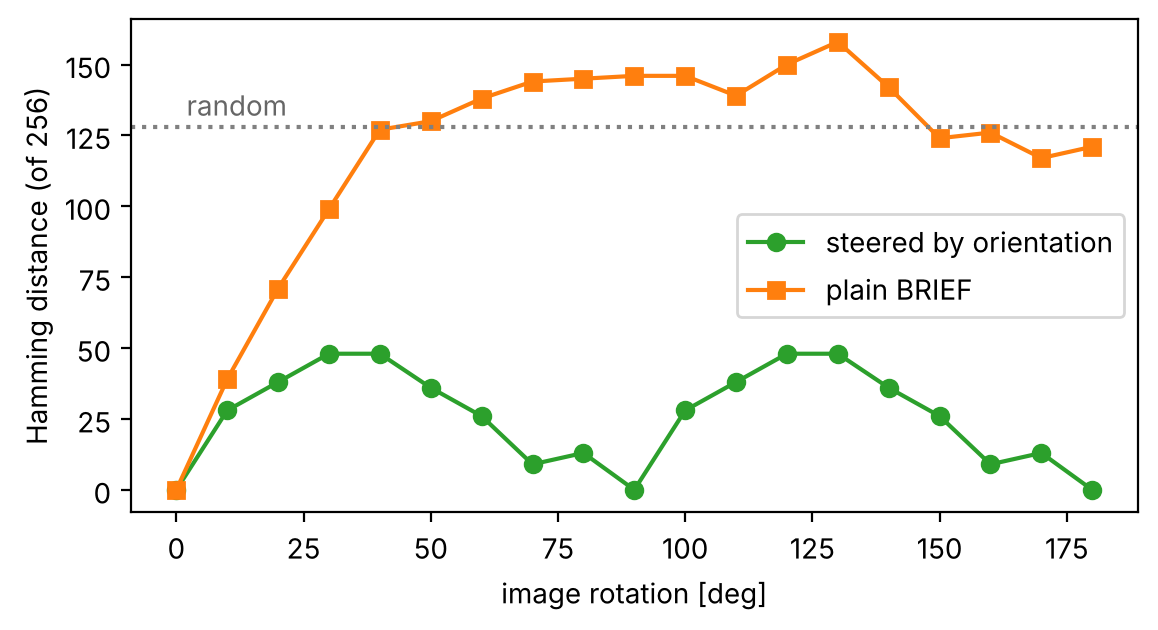

In [3]:
img = image.garden_texture(301, 301, np.random.default_rng(2))
kp = np.array([[150.0, 150.0]])
d0s = ft.describe(img, kp, ft.orientation(img, kp))
d0u = ft.describe(img, kp, None)
angles = np.arange(0, 181, 10)
steered, unsteered = [], []
for a in angles:
    R = cv2.getRotationMatrix2D((150, 150), a, 1.0)
    rot = cv2.warpAffine(img.astype(np.float32), R, (301, 301), flags=cv2.INTER_LINEAR).astype(float)
    steered.append(ft.hamming(d0s, ft.describe(rot, kp, ft.orientation(rot, kp)))[0, 0])
    unsteered.append(ft.hamming(d0u, ft.describe(rot, kp, None))[0, 0])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(angles, steered, "o-", color="tab:green", label="steered by orientation")
ax.plot(angles, unsteered, "s-", color="tab:orange", label="plain BRIEF")
ax.axhline(128, color="0.5", ls=":"); ax.text(2, 132, "random", color="0.4")
ax.set_xlabel("image rotation [deg]"); ax.set_ylabel("Hamming distance (of 256)"); ax.legend();

## 3. Why the ratio test works

For each feature of view 0, compare the distance to its best match with the distance to the second best. Correct
matches (known from the homography) have a clearly better best match; wrong ones do not. The threshold 0.8 separates
them.

kept by ratio < 0.8: 87% of correct, 31% of wrong


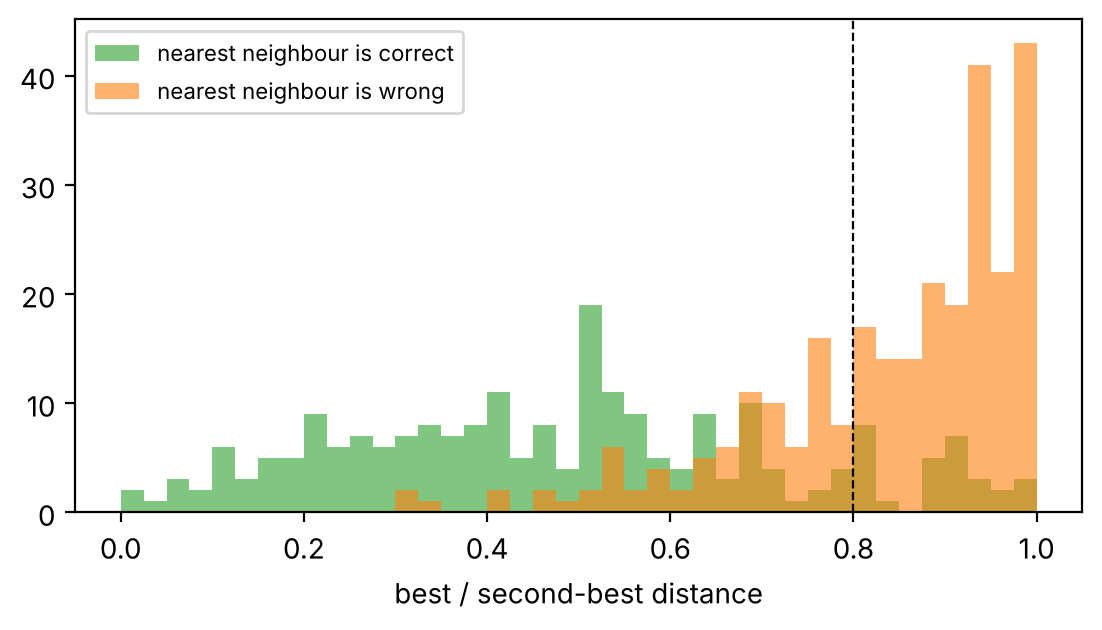

In [4]:
H = image.plane_homography(K, np.radians(20))
img1 = image.warp(garden, H)
k0 = ft.detect(ft.shi_tomasi(garden), 500); k1 = ft.detect(ft.shi_tomasi(img1), 500)
d0 = ft.describe(garden, k0, ft.orientation(garden, k0)); d1 = ft.describe(img1, k1, ft.orientation(img1, k1))
D = ft.hamming(d0, d1)
order = np.argsort(D, axis=1)
ratio = D[np.arange(len(k0)), order[:, 0]] / np.maximum(D[np.arange(len(k0)), order[:, 1]], 1)
correct = np.linalg.norm(image.apply_homography(H, k0) - k1[order[:, 0]], axis=1) < 3.0
fig, ax = plt.subplots(figsize=(6.5, 3.2))
bins = np.linspace(0, 1, 41)
ax.hist(ratio[correct], bins, alpha=0.6, color="tab:green", label="nearest neighbour is correct")
ax.hist(ratio[~correct], bins, alpha=0.6, color="tab:orange", label="nearest neighbour is wrong")
ax.axvline(0.8, color="k", ls="--", lw=0.8)
ax.set_xlabel("best / second-best distance"); ax.legend(fontsize=8);
print(f"kept by ratio < 0.8: {np.mean(ratio[correct] < 0.8):.0%} of correct, {np.mean(ratio[~correct] < 0.8):.0%} of wrong")

## 4. The lawn in the wind

On a rigid planar texture the lawn matches very well — its random blades are distinctive. Real grass is not rigid.
Rotating each blade about its root by a few degrees between the two images (wind, or the mower brushing it) destroys
most correspondences: the descriptor compares the same pixels, but they now belong to different blades.

In [5]:
H10 = image.plane_homography(K, np.radians(10))
for sway_deg in [0, 3, 6, 12]:
    img1 = image.warp(image.lawn_texture(rng=np.random.default_rng(0), sway=np.radians(sway_deg),
                                         sway_rng=np.random.default_rng(5)), H10)
    p0, p1, ok = match_views(lawn, img1, H10)
    # LK on the same corners, using the true displacement as reference
    pts = ft.detect(ft.shi_tomasi(lawn), 300, border=40)
    tr, st = flow.lucas_kanade(lawn, img1, pts, levels=3)
    err = np.linalg.norm(tr - image.apply_homography(H10, pts), axis=1)
    print(f"wind {sway_deg:2d} deg: {ok.sum():3d} correct of {len(ok):3d} matches | "
          f"LK: {np.mean(st):.0%} tracked, {np.mean(err[st] < 1.0):.0%} of them within 1 px")

wind  0 deg: 243 correct of 246 matches | LK: 80% tracked, 92% of them within 1 px


wind  3 deg:  75 correct of  80 matches | LK: 79% tracked, 92% of them within 1 px


wind  6 deg:  48 correct of  59 matches | LK: 79% tracked, 87% of them within 1 px


wind 12 deg:  15 correct of  30 matches | LK: 70% tracked, 70% of them within 1 px


## 5. Lucas–Kanade and the aperture problem (Proposition 5.6)

A point on a straight edge has a singular structure tensor: only the motion across the edge is observable. The tracker
reports it with its status flag.

In [6]:
sq = np.zeros((120, 120)); sq[40:80, 40:80] = 1.0
sq1 = image.warp(sq, np.array([[1, 0, 2.0], [0, 1, 3.0], [0, 0, 1.0]]))
pts = np.array([[40.0, 40.0], [60.0, 40.0], [60.0, 60.0]])          # corner, edge, flat
new, ok = flow.lucas_kanade(sq, sq1, pts, levels=1, min_eig=1e-4)
for name, p, n, o in zip(["corner", "edge", "flat"], pts, new, ok):
    print(f"{name:>6}: displacement {n - p}, status {o}   (true (2, 3))")

corner: displacement [2. 3.], status True   (true (2, 3))
  edge: displacement [0. 0.], status False   (true (2, 3))
  flat: displacement [0. 0.], status False   (true (2, 3))


## 6. RANSAC's adaptive stopping (Proposition 5.8)

Homography RANSAC on synthetic correspondences with a known inlier ratio: the number of samples actually drawn,
against the formula $N=\log(1-p)/\log(1-w^4)$.

In [7]:
rng = np.random.default_rng(1)
src = rng.uniform([0, 0], [640, 480], size=(300, 2))
dst_true = image.apply_homography(H, src)
print(f"{'w':>5} {'formula':>8} {'drawn (median of 20)':>22} {'inliers found':>14}")
for w in [0.9, 0.7, 0.5, 0.3]:
    its, found = [], []
    for t in range(20):
        dst = dst_true + rng.normal(0, 0.5, src.shape)
        out = rng.random(len(src)) > w
        dst[out] = rng.uniform([0, 0], [640, 480], size=(out.sum(), 2))
        res = ransac.homography_ransac(src, dst, 2.0, rng=rng)
        its.append(res.iterations); found.append(res.inliers[~out].mean())
    print(f"{w:5.1f} {ransac.required_iterations(w, 4):8d} {np.median(its):22.0f} {np.mean(found):14.1%}")

    w  formula   drawn (median of 20)  inliers found
  0.9        5                      8         100.0%


  0.7       17                     29          99.9%


  0.5       72                    148          99.9%


  0.3      567                    892          99.9%


RANSAC draws *more* samples than the formula. It does not know $w$: it estimates it from its best consensus set so
far, and a homography fitted to four noisy points is slightly off, so its consensus set misses a few true inliers.
Because $N$ depends on $w^s$, a slightly low estimate of $w$ costs many samples. Refitting the model on the consensus
set inside the loop before counting (LO-RANSAC) recovers most of the gap.

## 7. OpenCV's ORB

ORB adds an image pyramid (scale invariance) and FAST corners to what we built. On the 30° garden pair:

In [8]:
H30 = image.plane_homography(K, np.radians(30))
g1 = image.warp(garden, H30)
orb = cv2.ORB_create(nfeatures=500)
kp0, ds0 = orb.detectAndCompute((garden * 255).astype(np.uint8), None)
kp1, ds1 = orb.detectAndCompute((g1 * 255).astype(np.uint8), None)
bf = cv2.BFMatcher(cv2.NORM_HAMMING)
good = [m for m, n in bf.knnMatch(ds0, ds1, k=2) if m.distance < 0.8 * n.distance]
q0 = np.array([kp0[m.queryIdx].pt for m in good]); q1 = np.array([kp1[m.trainIdx].pt for m in good])
ok_cv = np.linalg.norm(image.apply_homography(H30, q0) - q1, axis=1) < 3.0
_, _, ok_ours = match_views(garden, g1, H30)
print(f"OpenCV ORB : {len(good)} matches, precision {ok_cv.mean():.0%}")
print(f"ours       : {len(ok_ours)} matches, precision {ok_ours.mean():.0%}")

OpenCV ORB : 203 matches, precision 94%
ours       : 176 matches, precision 78%


## 8. Try it yourself

* In section 3, set `ratio=1.0` in `ft.match` (no ratio test) and `mutual=False`. How does the precision change?
* In section 4, track with LK between *consecutive* frames of a slowly increasing wind instead of one big change.
  Does tracking survive longer than matching? What does that suggest for the mower's front-end?
* Make the lawn far away: `image.warp(lawn, ...)` with a homography that shrinks it by 4, then blur. How many corners
  survive? (Hint: the texture falls below the pixel size.)